# AUPRC by quintile of 2019 wetland pixels per cell

AUPRC for the hurdle classifier (any 2019 wetland in the cell developed by 2024, `n_developed > 0`), split by quintile of how many 30m wetland pixels the cell held in 2019. Runs: `results/hurdle_clf_mlp_300m_bce` and `results/hurdle_clf_mlp_3km_bce`, both BCE loss. Figure names carry a `_bce` suffix so they sit next to figures from other runs at the same resolution instead of overwriting them.

Each bar is the mean over the 5 spatial folds and the error bar is the standard deviation across folds. The gray line across each bar is the positive rate in that bin, which is the AUPRC a random ranking would get. Since the positive rate moves a lot across bins, compare each bar to its own gray line, not across bins.

Validation bars are orange and train bars are blue.

In [70]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RUNS = {
    "300m": ROOT / "results/hurdle_clf_mlp_300m_bce",
    "3km": ROOT / "results/hurdle_clf_mlp_3km_bce",
}
# suffix names the loss so PNGs from other runs of the same resolution (BCE, focal, 300m _64pos, _128pos) are not overwritten
FIG_SUFFIX = {"300m": "_bce", "3km": "_bce"}
FIG_DIR = ROOT / "results/figures/prediction_analysis"
FIG_DIR.mkdir(parents=True, exist_ok=True)

for res, d in RUNS.items():
    m = json.loads((d / "manifest.json").read_text())
    c = m["cells"]
    print(f"{res:>5}  {m['model']}  {m['loss']}  cells {c['path']} built {c['built_utc']} "
          f"commit {c['git_commit'][:7]}  n_cells {c['n_cells']:,}  "
          f"positive share {c['share_cells_with_any_developed']:.2%}")

 300m  CellMultiLayerPerceptronClassifier  BCE loss  cells data/cells_2019_2024_300m built 2026-10-27T21:20:10Z commit 661cfd1  n_cells 1,170,463  positive share 3.06%
  3km  CellMultiLayerPerceptronClassifier  BCE loss  cells data/cells_2019_2024_3km built 2026-11-03T20:21:41Z commit 52ebf47  n_cells 23,900  positive share 28.60%


In [71]:
# same hex values as reporting.TRAIN_COLOR / VAL_COLOR
TRAIN_COLOR = "#0072B2"
VAL_COLOR = "#D55E00"
CHANCE_COLOR = "#52514e"
RES_TITLE = {"300m": "300 m cells", "3km": "3 km cells"}

plt.rcParams.update({"font.size": 14, "axes.titlesize": 16, "axes.labelsize": 15,
                     "xtick.labelsize": 12, "ytick.labelsize": 13, "legend.fontsize": 13})


def plot_auprc_by_bin(s, xlabel, title, color, bar_label):
    """s is indexed by bin label in plot order, with the columns built by summarize_bins."""
    x = np.arange(len(s))
    width = 0.6

    fig, ax = plt.subplots(figsize=(9, 5.5))
    # pandas std is ddof=1, so a bin scored in only 1 fold would get NaN and no error bar
    ax.bar(x, s["auprc_mean"], width=width, color=color, label=bar_label,
           yerr=s["auprc_std"], error_kw=dict(ecolor="#0b0b0b", elinewidth=1.5, capsize=6, capthick=1.5),
           zorder=2)
    ax.hlines(s["positive_rate"], x - width / 2, x + width / 2, color=CHANCE_COLOR, lw=2.5, ls="--",
              label="Positive rate (random ranking)", zorder=3)

    ticks = [f"{b}\n{s.loc[b, 'n_cells']:,} cells\n{s.loc[b, 'n_pos']:,} pos" for b in s.index]
    ax.set_xticks(x, ticks)
    # headroom above 1 so the legend clears bars near 0.9 at 3 km
    ax.set_ylim(0, 1.15)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_xlabel(xlabel)
    ax.set_ylabel("AUPRC")
    ax.set_title(title)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, loc="upper left", ncol=2, fontsize=12)
    fig.tight_layout()
    return fig

## Validation

Bins are quintiles of `n_wetland` taken within each resolution, so each bar holds about a fifth of that resolution's cells.

These are computed straight from the per cell predictions in `fold_*/val_preds.npz`. Quintile edges come from all validation cells pooled across the 5 folds (each cell is in exactly one validation fold), so every fold is scored on the same edges. The train figures below reuse these same edges.

`n_wetland` is an integer with a lot of ties (at 300 m the cell holds at most 100 pixels, and about 20% of cells are fully wetland at exactly 100), so the cut keeps tied cells in the same bin rather than splitting them to force exactly 20%. Bin sizes therefore differ by a few percent. At 300 m the top quintile is only the fully wetland cells.

In [72]:
def load_preds(d, split):
    """split is "val" or "train". Train has every cell 4 times, once per fold it was trained on."""
    parts = []
    for p in sorted(d.glob(f"fold_*/{split}_preds.npz")):
        z = np.load(p)
        parts.append(pd.DataFrame({"fold": int(p.parent.name.split("_")[1]), "prob": z["prob"],
                                   "y": z["any"], "n_wetland": z["n_wetland"], "cell_idx": z["cell_idx"]}))
    return pd.concat(parts, ignore_index=True)


def quintile_edges(n):
    edges = np.quantile(n, [0.2, 0.4, 0.6, 0.8])
    assert np.unique(edges).size == 4, f"quintile edges collapse on ties: {edges}"
    return edges


def quintile_labels(n, edges, n_min, n_max, prefix="Q"):
    # side="left" puts n == edge in the lower bin, so bin i is (edge[i-1], edge[i]]
    q = np.searchsorted(edges, n, side="left")
    # n is an integer, so write each bin as the integer range it actually covers
    lo = np.r_[n_min, np.floor(edges) + 1].astype(int)
    hi = np.r_[np.floor(edges), n_max].astype(int)
    names = [f"{prefix}{i + 1}\n{a:,}" if a == b else f"{prefix}{i + 1}\n{a:,} to {b:,}"
             for i, (a, b) in enumerate(zip(lo, hi))]
    return pd.Categorical.from_codes(q, names)


def summarize_bins(v, col):
    """Per fold AUPRC within each bin of v[col], then mean and std over folds.

    Cell and positive counts are unique cells, so train (each cell in 4 folds) isn't counted 4 times.
    """
    per_fold = (v.groupby([col, "fold"], observed=True)
                 .apply(lambda g: average_precision_score(g["y"], g["prob"]) if g["y"].any() else np.nan)
                 .rename("auprc").reset_index())
    s = per_fold.groupby(col, observed=True)["auprc"].agg(
        folds_scored="count", auprc_mean="mean", auprc_std="std", auprc_min="min", auprc_max="max")
    cells = v.drop_duplicates("cell_idx").groupby(col, observed=True)["y"].agg(n_cells="size", n_pos="sum")
    s = cells.astype(int).join(s)
    s["positive_rate"] = s["n_pos"] / s["n_cells"]
    s.index = s.index.astype(str)
    return s


val_preds, edges, quintile_summary = {}, {}, {}
for res, d in RUNS.items():
    v = load_preds(d, "val")
    assert len(v) == json.loads((d / "manifest.json").read_text())["cells"]["n_cells"]
    n = v["n_wetland"].to_numpy()
    edges[res] = (quintile_edges(n), n.min(), n.max())
    v["quintile"] = quintile_labels(n, *edges[res])
    val_preds[res] = v

    s = summarize_bins(v, "quintile")
    quintile_summary[res] = s
    print(res)
    display(s.round(3))

300m


,n_cells,n_pos,folds_scored,auprc_mean,auprc_std,auprc_min,auprc_max,positive_rate
quintile,,,,,,,,
Q1\n1 to 12,246170,10178,5,0.339,0.031,0.295,0.374,0.041
Q2\n13 to 31,227587,10100,5,0.431,0.035,0.388,0.479,0.044
Q3\n32 to 62,231811,9413,5,0.424,0.052,0.354,0.498,0.041
Q4\n63 to 99,233471,5824,5,0.347,0.090,0.232,0.484,0.025
Q5\n100,231424,337,5,0.130,0.040,0.072,0.175,0.001


3km


,n_cells,n_pos,folds_scored,auprc_mean,auprc_std,auprc_min,auprc_max,positive_rate
quintile,,,,,,,,
Q1\n1 to 363,4792,1282,5,0.806,0.030,0.755,0.827,0.268
"Q2\n364 to 1,089",4787,1449,5,0.864,0.028,0.833,0.892,0.303
"Q3\n1,090 to 2,223",4762,1526,5,0.860,0.027,0.823,0.890,0.320
"Q4\n2,224 to 3,956",4779,1388,5,0.849,0.018,0.829,0.871,0.290
"Q5\n3,957 to 10,000",4780,1190,5,0.757,0.027,0.725,0.795,0.249


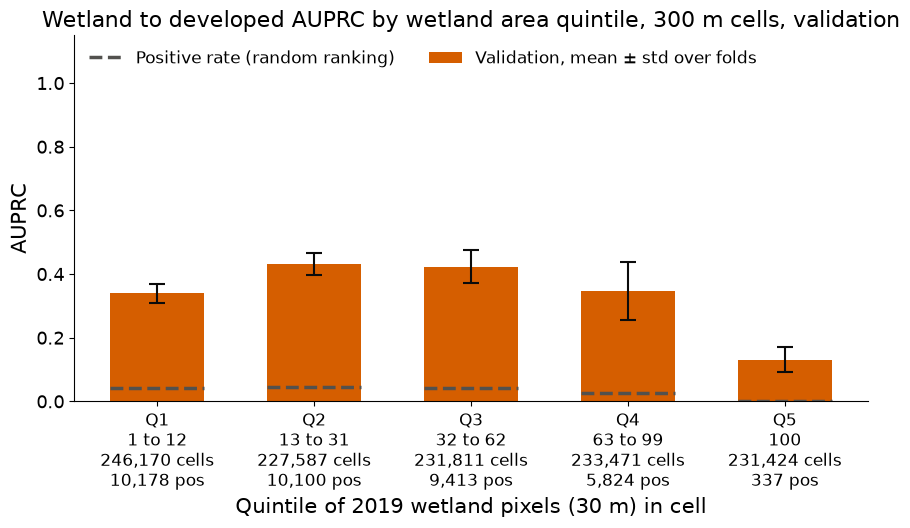

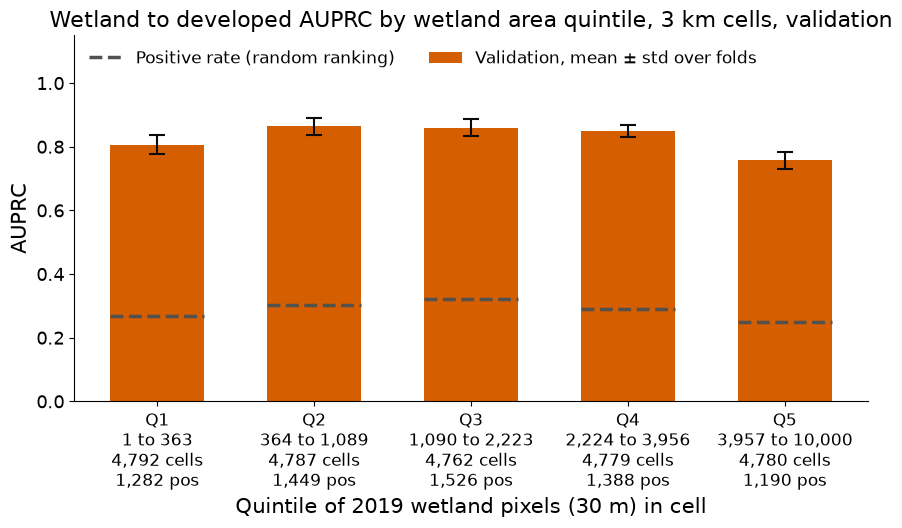

In [73]:
for res in RUNS:
    fig = plot_auprc_by_bin(quintile_summary[res], "Quintile of 2019 wetland pixels (30 m) in cell",
                            f"Wetland to developed AUPRC by wetland area quintile, {RES_TITLE[res]}, validation",
                            VAL_COLOR, "Validation, mean ± std over folds")
    fig.savefig(FIG_DIR / f"auprc_by_n_wetland_quintile_{res}{FIG_SUFFIX[res]}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

## Train

Same quintile edges as validation, scored on `fold_*/train_preds.npz`: each fold's model scored on the cells it was trained on. Every cell sits in 4 of the 5 training sets, so the cell and positive counts under each bar are unique cells and match the validation figure. A big gap between a train bar and its validation bar means the model has memorized that bin rather than learned something that carries to held out regions.

In [74]:
train_preds, train_quintile_summary = {}, {}
for res, d in RUNS.items():
    t = load_preds(d, "train")
    # every cell is a training cell in exactly 4 folds
    assert len(t) == 4 * len(val_preds[res])
    t["quintile"] = quintile_labels(t["n_wetland"].to_numpy(), *edges[res])
    train_preds[res] = t

    s = summarize_bins(t, "quintile")
    train_quintile_summary[res] = s
    print(res)
    display(s.round(3))

300m


,n_cells,n_pos,folds_scored,auprc_mean,auprc_std,auprc_min,auprc_max,positive_rate
quintile,,,,,,,,
Q1\n1 to 12,246170,10178,5,0.380,0.007,0.372,0.389,0.041
Q2\n13 to 31,227587,10100,5,0.465,0.008,0.457,0.477,0.044
Q3\n32 to 62,231811,9413,5,0.463,0.015,0.442,0.484,0.041
Q4\n63 to 99,233471,5824,5,0.399,0.024,0.361,0.426,0.025
Q5\n100,231424,337,5,0.181,0.017,0.160,0.207,0.001


3km


,n_cells,n_pos,folds_scored,auprc_mean,auprc_std,auprc_min,auprc_max,positive_rate
quintile,,,,,,,,
Q1\n1 to 363,4792,1282,5,0.818,0.008,0.812,0.832,0.268
"Q2\n364 to 1,089",4787,1449,5,0.871,0.007,0.864,0.878,0.303
"Q3\n1,090 to 2,223",4762,1526,5,0.868,0.007,0.858,0.876,0.320
"Q4\n2,224 to 3,956",4779,1388,5,0.857,0.005,0.850,0.862,0.290
"Q5\n3,957 to 10,000",4780,1190,5,0.777,0.008,0.768,0.788,0.249


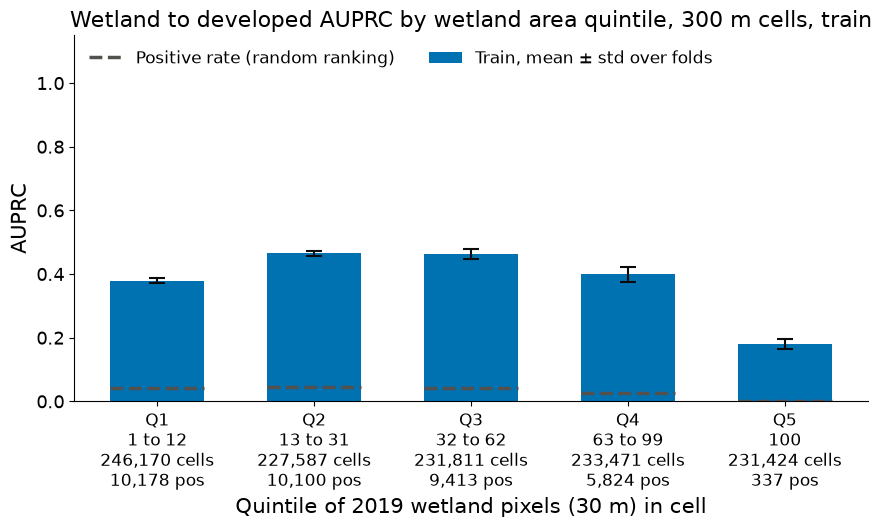

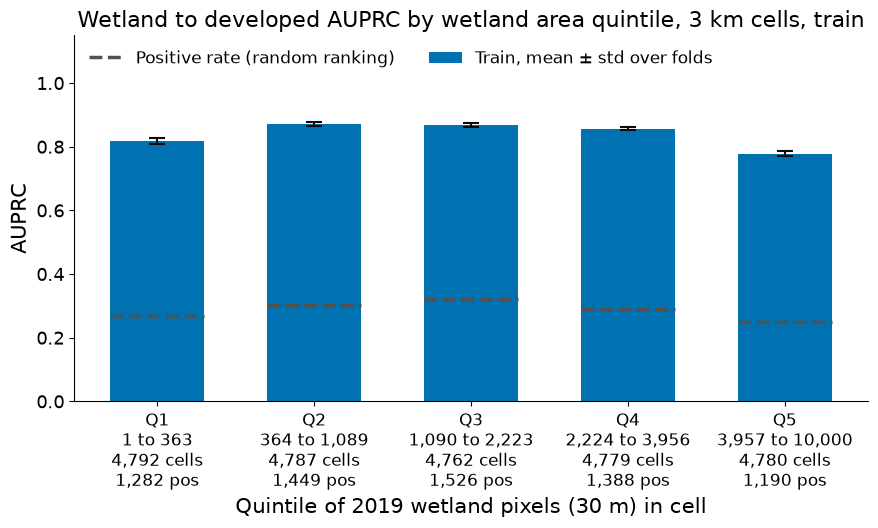

In [75]:
for res in RUNS:
    fig = plot_auprc_by_bin(train_quintile_summary[res], "Quintile of 2019 wetland pixels (30 m) in cell",
                            f"Wetland to developed AUPRC by wetland area quintile, {RES_TITLE[res]}, train",
                            TRAIN_COLOR, "Train, mean ± std over folds")
    fig.savefig(FIG_DIR / f"auprc_by_n_wetland_quintile_train_{res}{FIG_SUFFIX[res]}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

# Splitting the 3 km top quintile further

The 3 km Q5 cells (3,957 to 10,000 wetland pixels) are split again into five equal count sub bins, Q5.1 to Q5.5, with the same rule as the quintiles above: edges taken from all Q5 validation cells pooled, tied pixel counts kept together. That gives 956 cells per sub bin. Equal counts were picked over fixed 1,000 pixel steps so every AUPRC is estimated from about the same number of cells (fixed steps would run from 393 to 1,197 cells).

Top panel is AUPRC, mean ± std over the 5 folds, with the positive rate as the gray line, read the same way as the bar charts above. Bottom panel is the cell count in each sub bin, split into cells with any conversion and cells with none.

Q5.5 has only 35 positives in total, 4 to 9 per fold, so its AUPRC and std are much noisier than the other sub bins.

In [76]:
v = val_preds["3km"]
q5_3km = v[v["quintile"] == v["quintile"].cat.categories[-1]].copy()
n = q5_3km["n_wetland"].to_numpy()
q5_3km["sub_bin"] = quintile_labels(n, quintile_edges(n), n.min(), n.max(), prefix="Q5.")
q5_sub_summary = summarize_bins(q5_3km, "sub_bin")
display(q5_sub_summary.round(3))

,n_cells,n_pos,folds_scored,auprc_mean,auprc_std,auprc_min,auprc_max,positive_rate
sub_bin,,,,,,,,
"Q5.1\n3,957 to 4,759",956,363,5,0.832,0.041,0.787,0.873,0.380
"Q5.2\n4,760 to 5,858",956,290,5,0.783,0.025,0.747,0.808,0.303
"Q5.3\n5,859 to 7,475",956,313,5,0.783,0.022,0.757,0.814,0.327
"Q5.4\n7,476 to 9,570",956,189,5,0.632,0.071,0.550,0.717,0.198
"Q5.5\n9,571 to 10,000",956,35,5,0.363,0.124,0.231,0.517,0.037


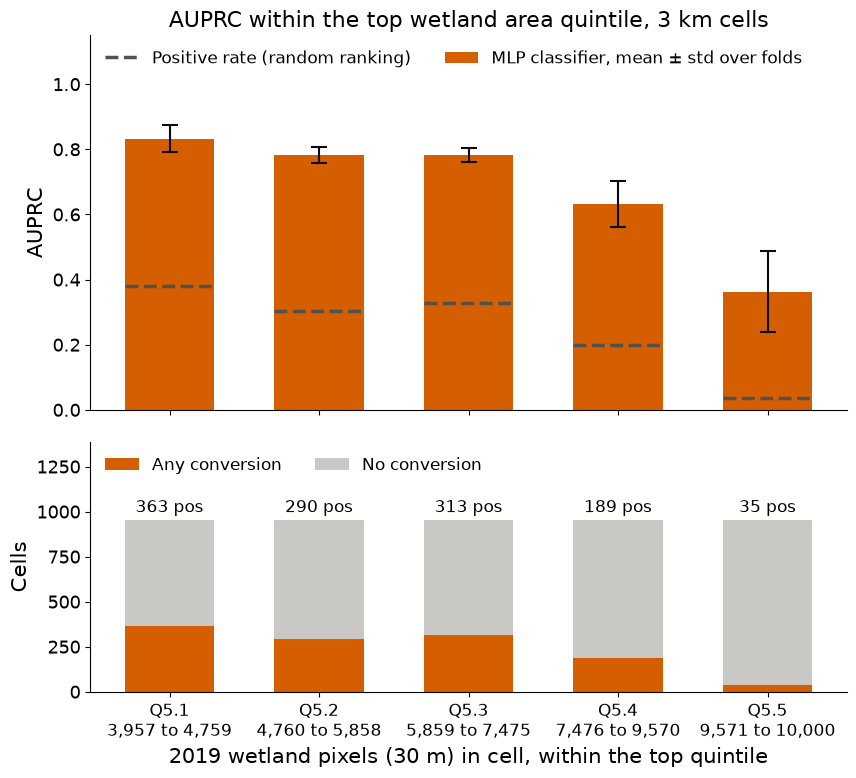

In [77]:
NEG_COLOR = "#c9c8c4"


def plot_auprc_and_positives(s, xlabel, title):
    x = np.arange(len(s))
    width = 0.6
    fig, (ax_a, ax_n) = plt.subplots(2, 1, figsize=(9, 8), sharex=True, gridspec_kw=dict(height_ratios=[3, 2]))

    ax_a.bar(x, s["auprc_mean"], width=width, color=VAL_COLOR, label="MLP classifier, mean ± std over folds",
             yerr=s["auprc_std"], error_kw=dict(ecolor="#0b0b0b", elinewidth=1.5, capsize=6, capthick=1.5),
             zorder=2)
    ax_a.hlines(s["positive_rate"], x - width / 2, x + width / 2, color=CHANCE_COLOR, lw=2.5, ls="--",
                label="Positive rate (random ranking)", zorder=3)
    ax_a.set_ylim(0, 1.15)
    ax_a.set_yticks(np.arange(0, 1.01, 0.2))
    ax_a.set_ylabel("AUPRC")
    ax_a.set_title(title)
    ax_a.legend(frameon=False, loc="upper left", ncol=2, fontsize=12)

    n_neg = s["n_cells"] - s["n_pos"]
    ax_n.bar(x, s["n_pos"], width=width, color=VAL_COLOR, label="Any conversion", zorder=2)
    ax_n.bar(x, n_neg, width=width, bottom=s["n_pos"], color=NEG_COLOR, label="No conversion", zorder=2)
    for xi, (p, n) in enumerate(zip(s["n_pos"], s["n_cells"])):
        ax_n.text(xi, n * 1.02, f"{p:,} pos", ha="center", va="bottom", fontsize=12)
    ax_n.set_ylim(0, s["n_cells"].max() * 1.45)
    ax_n.set_ylabel("Cells")
    ax_n.legend(frameon=False, loc="upper left", ncol=2, fontsize=12)

    ax_n.set_xticks(x, s.index)
    ax_n.set_xlabel(xlabel)
    for ax in (ax_a, ax_n):
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    fig.tight_layout()
    return fig


fig = plot_auprc_and_positives(q5_sub_summary, "2019 wetland pixels (30 m) in cell, within the top quintile",
                               "AUPRC within the top wetland area quintile, 3 km cells")
fig.savefig(FIG_DIR / f"auprc_q5_sub_bins_3km{FIG_SUFFIX['3km']}.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

# Distribution of predicted probabilities

Classifier probabilities for train and validation cells at each resolution, split by whether the cell actually had any wetland converted to developed by 2024. Each class is normalized to its own total, so a bar is the percent of that class's cells in the bin. Without that, the 3% positives at 300 m would be invisible next to the negatives.

Validation pools the 5 folds (each cell once). Train pools the 5 folds' training sets, so every cell shows up 4 times, scored by 4 different models.

Both runs are BCE loss. Neither is calibrated, so read these for separation between the two classes, not for the probability values themselves.

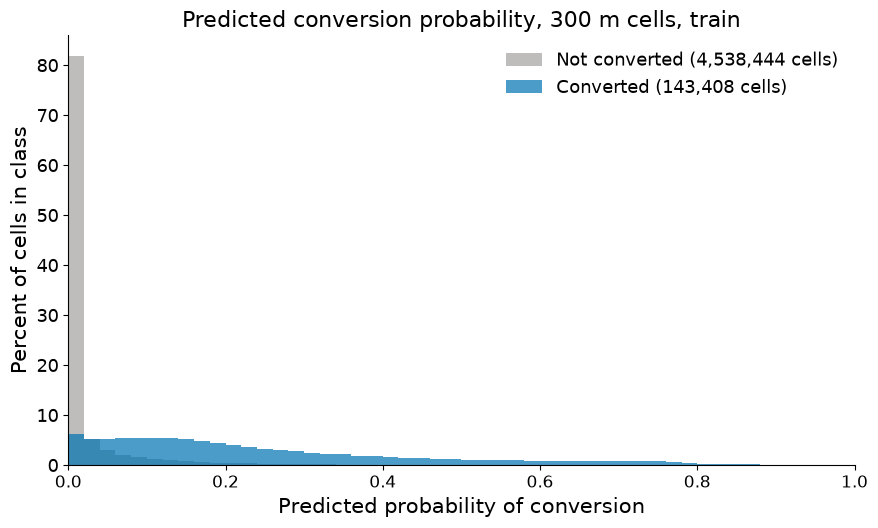

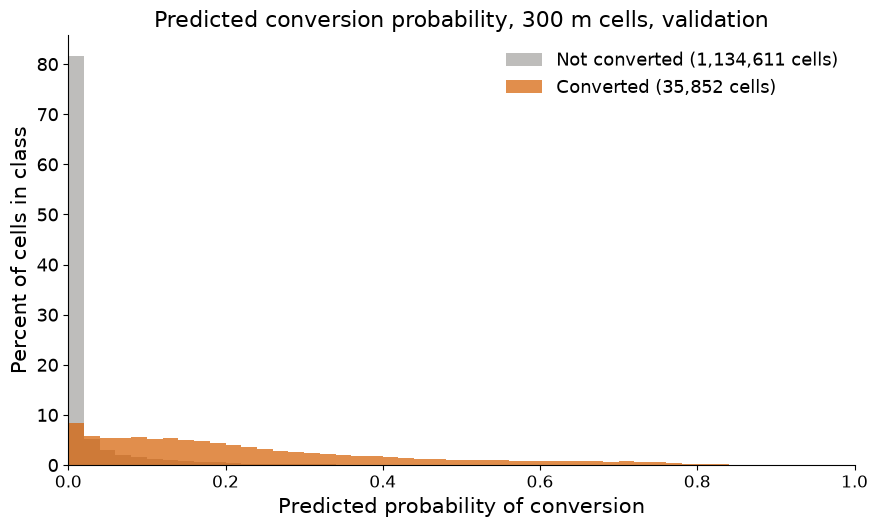

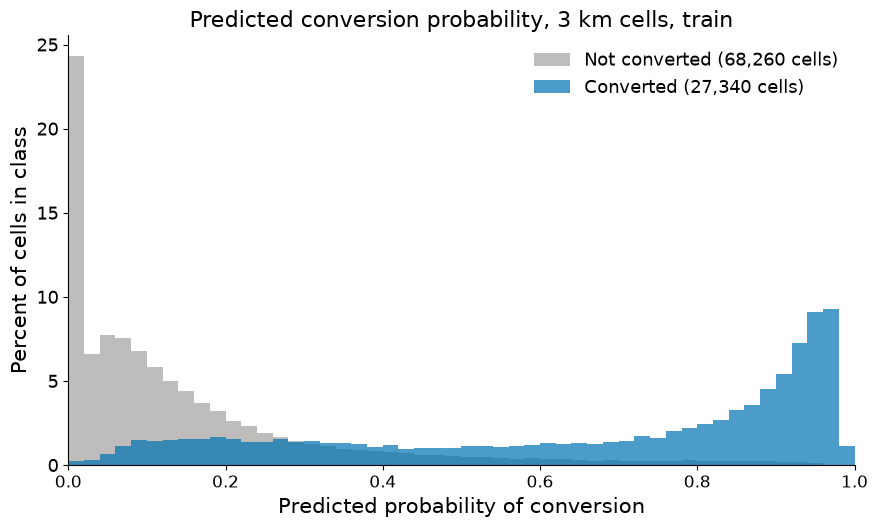

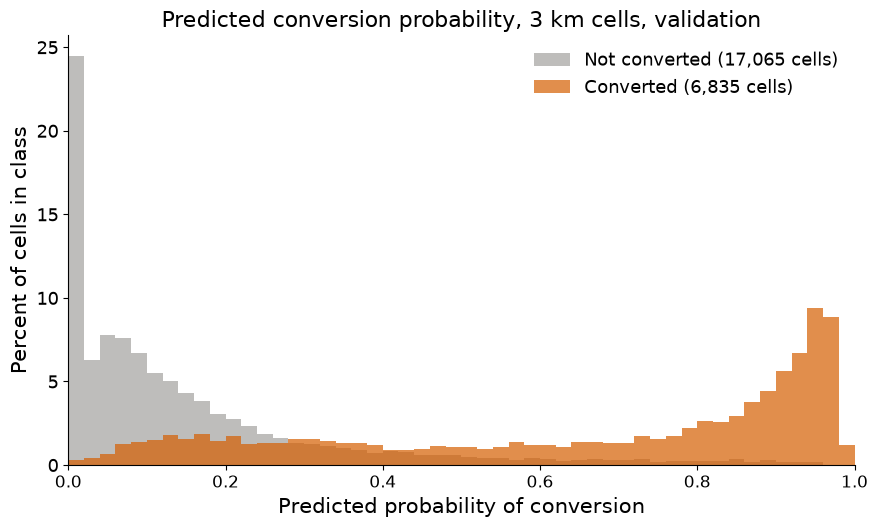

In [78]:
NOT_CONVERTED_COLOR = "#a3a29e"
PROB_BINS = np.linspace(0, 1, 51)


def plot_prob_hist(v, title, color):
    fig, ax = plt.subplots(figsize=(9, 5.5))
    for is_pos, c, name, kw in ((False, NOT_CONVERTED_COLOR, "Not converted", dict(alpha=0.7)),
                                (True, color, "Converted", dict(alpha=0.7))):
        p = v.loc[v["y"] == is_pos, "prob"].to_numpy()
        ax.hist(p, bins=PROB_BINS, weights=np.full(len(p), 100 / len(p)), color=c,
                label=f"{name} ({len(p):,} cells)", zorder=2, **kw)
    ax.set_xlim(0, 1)
    ax.set_xlabel("Predicted probability of conversion")
    ax.set_ylabel("Percent of cells in class")
    ax.set_title(title)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, loc="upper right")
    fig.tight_layout()
    return fig


for res in RUNS:
    for split, preds, color in (("train", train_preds, TRAIN_COLOR), ("validation", val_preds, VAL_COLOR)):
        fig = plot_prob_hist(preds[res], f"Predicted conversion probability, {RES_TITLE[res]}, {split}", color)
        fig.savefig(FIG_DIR / f"prob_hist_{split}_{res}{FIG_SUFFIX[res]}.png", dpi=200, bbox_inches="tight", facecolor="white")
        plt.show()

# Map of 300 m validation predictions

Every cell is in exactly one validation fold, so stitching the 5 `val_preds.npz` files together gives one out of fold prediction per cell across the whole state, each scored by the model that never trained on that cell's spatial block. Train predictions would show the model's memory, not its skill, so they are not mapped.

Color is the cell's percentile rank among all 1,170,463 validation cells, not the raw probability. The probabilities aren't calibrated and about 80% of cells sit below 0.02, so a linear probability scale would look empty. Rank shows where the model puts cells relative to each other, which is what AUPRC scores. Ranks pool predictions from 5 different models, so a visible edge along a spatial block boundary can be a fold seam rather than something on the ground.

The right panel is what actually happened: cells with any 2019 wetland developed by 2024 (3.06% of cells). White is cells with no 2019 wetland at all.

Cells are tiled from each spatial block's own corner, so where blocks meet there are thin partial cells that land on the same 300 m map square as a full neighbor. About 3% of cells collide like this. The full cell is drawn and the sliver is hidden.

In [79]:
import geopandas as gpd
from pyproj import Transformer
from scipy.stats import rankdata


PIXEL_M = 30


def cell_rectangles_km(cell_xy, cell_rowcol, footprint, n):
    """Exact footprint of each cell as (n_cells, 4, 2) corners in EPSG:5070 km.

    Cells are tiled from each block's own corner, so cells on a block's far edge are cut short. Width and height in
    pixels aren't stored, but cell_xy is the mean of the footprint pixel centers, so they come back out of the
    offset between cell_xy and the cell's first pixel.
    """
    full = footprint == n * n
    # pixel centers sit at x_off + 30 col and y_off minus 30 row, same affine as build_cells
    x_off = np.unique(cell_xy[full, 0] - PIXEL_M * (cell_rowcol[full, 1] + (n - 1) / 2))
    y_off = np.unique(cell_xy[full, 1] + PIXEL_M * (cell_rowcol[full, 0] + (n - 1) / 2))
    assert x_off.size == 1 and y_off.size == 1
    fx = np.rint(2 * ((cell_xy[:, 0] - x_off[0]) / PIXEL_M - cell_rowcol[:, 1]) + 1)
    fy = np.rint(2 * ((y_off[0] - cell_xy[:, 1]) / PIXEL_M - cell_rowcol[:, 0]) + 1)
    assert np.array_equal(fx * fy, footprint)
    left = x_off[0] + PIXEL_M * (cell_rowcol[:, 1] - 0.5)
    top = y_off[0] - PIXEL_M * (cell_rowcol[:, 0] - 0.5)
    right, bottom = left + PIXEL_M * fx, top - PIXEL_M * fy
    return np.stack([np.c_[left, bottom], np.c_[right, bottom], np.c_[right, top], np.c_[left, top]], axis=1) / 1000


def build_map_grids(res, exact=False):
    """Rank and truth grids for one resolution's validation predictions, snapped to a grid of that cell size.

    Rank is percentile among that resolution's validation cells. Returns grids with NaN where there is no cell,
    and the extent in EPSG:5070 km for imshow. With exact=True it also returns every cell's true footprint
    rectangle, which draw_map uses instead of the grid, so no cell is hidden.
    """
    m = json.loads((RUNS[res] / "manifest.json").read_text())["cells"]
    cell_dir, cell_m = ROOT / m["path"], m["cell_size_m"]
    cell_xy = np.load(cell_dir / "cell_xy.npy")
    footprint = np.load(cell_dir / "footprint_px.npy")

    v = val_preds[res]
    assert v["cell_idx"].is_unique and len(v) == len(cell_xy)
    idx = v["cell_idx"].to_numpy()
    rank_pct = np.empty(len(cell_xy))
    rank_pct[idx] = 100 * rankdata(v["prob"]) / len(v)
    converted = np.zeros(len(cell_xy), bool)
    converted[idx] = v["y"].to_numpy()

    # cell_xy is the footprint center in EPSG:5070 meters
    x0 = cell_xy[:, 0].min() - cell_m / 2
    y1 = cell_xy[:, 1].max() + cell_m / 2
    col = np.floor((cell_xy[:, 0] - x0) / cell_m).astype(int)
    row = np.floor((y1 - cell_xy[:, 1]) / cell_m).astype(int)
    shape = (row.max() + 1, col.max() + 1)

    # write small footprints first so a full cell overwrites a block edge sliver on the same square
    order = np.argsort(footprint, kind="stable")
    rank_grid = np.full(shape, np.nan)
    rank_grid[row[order], col[order]] = rank_pct[order]
    truth_grid = np.full(shape, np.nan)
    truth_grid[row[order], col[order]] = converted[order]
    n_drawn = np.isfinite(rank_grid).sum()
    print(f"{res}: grid {shape[0]} x {shape[1]}, {n_drawn:,} squares drawn from {len(cell_xy):,} cells "
          f"({1 - n_drawn / len(cell_xy):.1%} hidden behind a neighbor)")
    extent_km = np.array([x0, x0 + shape[1] * cell_m, y1 - shape[0] * cell_m, y1]) / 1000
    g = dict(rank=rank_grid, truth=truth_grid, extent_km=extent_km)
    if exact:
        n = cell_m // PIXEL_M
        g["verts"] = cell_rectangles_km(cell_xy, np.load(cell_dir / "cell_rowcol.npy"), footprint, n)
        g["rank_cells"], g["truth_cells"] = rank_pct, converted.astype(float)
        print(f"{res}: drawing all {len(cell_xy):,} cells at their exact footprint, "
              f"{(footprint < n * n).mean():.1%} of them cut short at a block edge")
    return g


fl = gpd.read_file(ROOT / "data/boundaries/cb_2023_us_state_500k/cb_2023_us_state_500k.shp")
fl = fl[fl["STUSPS"] == "FL"].to_crs("EPSG:5070")
fl["geometry"] = fl.scale(1 / 1000, 1 / 1000, origin=(0, 0))

map_grids = {"300m": build_map_grids("300m")}

300m: grid 2305 x 2681, 1,132,996 squares drawn from 1,170,463 cells (3.2% hidden behind a neighbor)


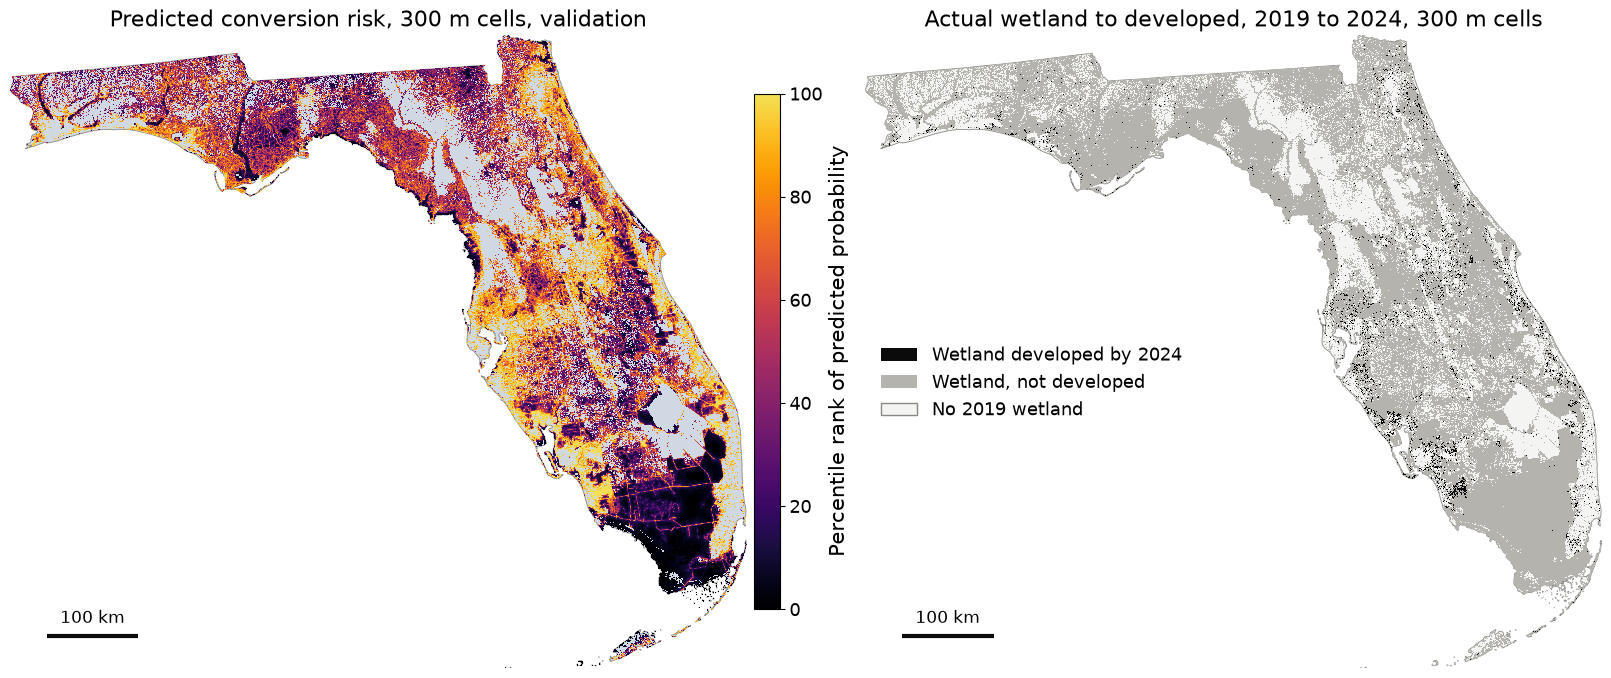

In [80]:
# dark is low risk and bright is high, stopped short of inferno's near white top so high cells stay visible
RANK_CMAP = plt.matplotlib.colors.ListedColormap(plt.get_cmap("inferno")(np.linspace(0, 0.92, 256)))
NO_CONVERSION_COLOR = "#b4b3ae"
CONVERTED_COLOR = "#0b0b0b"
LAND_COLOR = "#f4f4f2"
# land behind the risk map is blue gray so it reads apart from both the dark and the yellow ends
RANK_LAND_COLOR = "#cfd8e3"
truth_cmap = plt.matplotlib.colors.ListedColormap([NO_CONVERSION_COLOR, CONVERTED_COLOR])


def draw_map(ax, g, kind, xlim=None, ylim=None, scale_km=100):
    fl.plot(ax=ax, color=RANK_LAND_COLOR if kind == "rank" else LAND_COLOR, edgecolor="#8a8984", linewidth=0.6, zorder=1)
    cmap, vmax = (RANK_CMAP, 100) if kind == "rank" else (truth_cmap, 1)
    if "verts" in g:
        im = plt.matplotlib.collections.PolyCollection(g["verts"], array=g[f"{kind}_cells"], cmap=cmap,
                                                       edgecolors="face", linewidths=0.2, zorder=2)
        im.set_clim(0, vmax)
        ax.add_collection(im)
    else:
        im = ax.imshow(g[kind], extent=g["extent_km"], cmap=cmap, vmin=0, vmax=vmax, interpolation="nearest", zorder=2)
    ax.set_xlim(xlim if xlim is not None else g["extent_km"][:2])
    ax.set_ylim(ylim if ylim is not None else g["extent_km"][2:])
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(xlim is not None)
        s.set_color("#8a8984")
    # scale bar on a white box so it reads over dark low risk cells
    x_lo, x_hi = ax.get_xlim(); y_lo, y_hi = ax.get_ylim()
    w, h = x_hi - x_lo, y_hi - y_lo
    bx, by = x_lo + 0.05 * w, y_lo + 0.05 * h
    ax.add_patch(plt.Rectangle((bx - 0.02 * w, by - 0.025 * h), scale_km + 0.04 * w, 0.1 * h,
                               facecolor="white", edgecolor="none", alpha=0.85, zorder=3))
    ax.plot([bx, bx + scale_km], [by, by], color="#0b0b0b", lw=3, zorder=4, solid_capstyle="butt")
    ax.text(bx + scale_km / 2, by + 0.015 * h, f"{scale_km} km", ha="center", va="bottom", fontsize=12, zorder=4)
    return im


TRUTH_HANDLES = [plt.matplotlib.patches.Patch(facecolor=CONVERTED_COLOR, label="Wetland developed by 2024"),
                 plt.matplotlib.patches.Patch(facecolor=NO_CONVERSION_COLOR, label="Wetland, not developed"),
                 plt.matplotlib.patches.Patch(facecolor=LAND_COLOR, edgecolor="#8a8984", label="No 2019 wetland")]


def plot_state_map(res):
    g = map_grids[res]
    fig, (ax_p, ax_t) = plt.subplots(1, 2, figsize=(16, 8), layout="constrained")
    im = draw_map(ax_p, g, "rank")
    ax_p.set_title(f"Predicted conversion risk, {RES_TITLE[res]}, validation")
    draw_map(ax_t, g, "truth")
    ax_t.set_title(f"Actual wetland to developed, 2019 to 2024, {RES_TITLE[res]}")
    # the Gulf, west of the peninsula, is empty space for the legend
    ax_t.legend(handles=TRUTH_HANDLES, frameon=False, loc="center left", bbox_to_anchor=(0.0, 0.45), fontsize=13)
    cb = fig.colorbar(im, ax=ax_p, fraction=0.035, pad=0.01)
    cb.set_label("Percentile rank of predicted probability")
    fig.savefig(FIG_DIR / f"map_val_rank_{res}{FIG_SUFFIX[res]}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()


plot_state_map("300m")

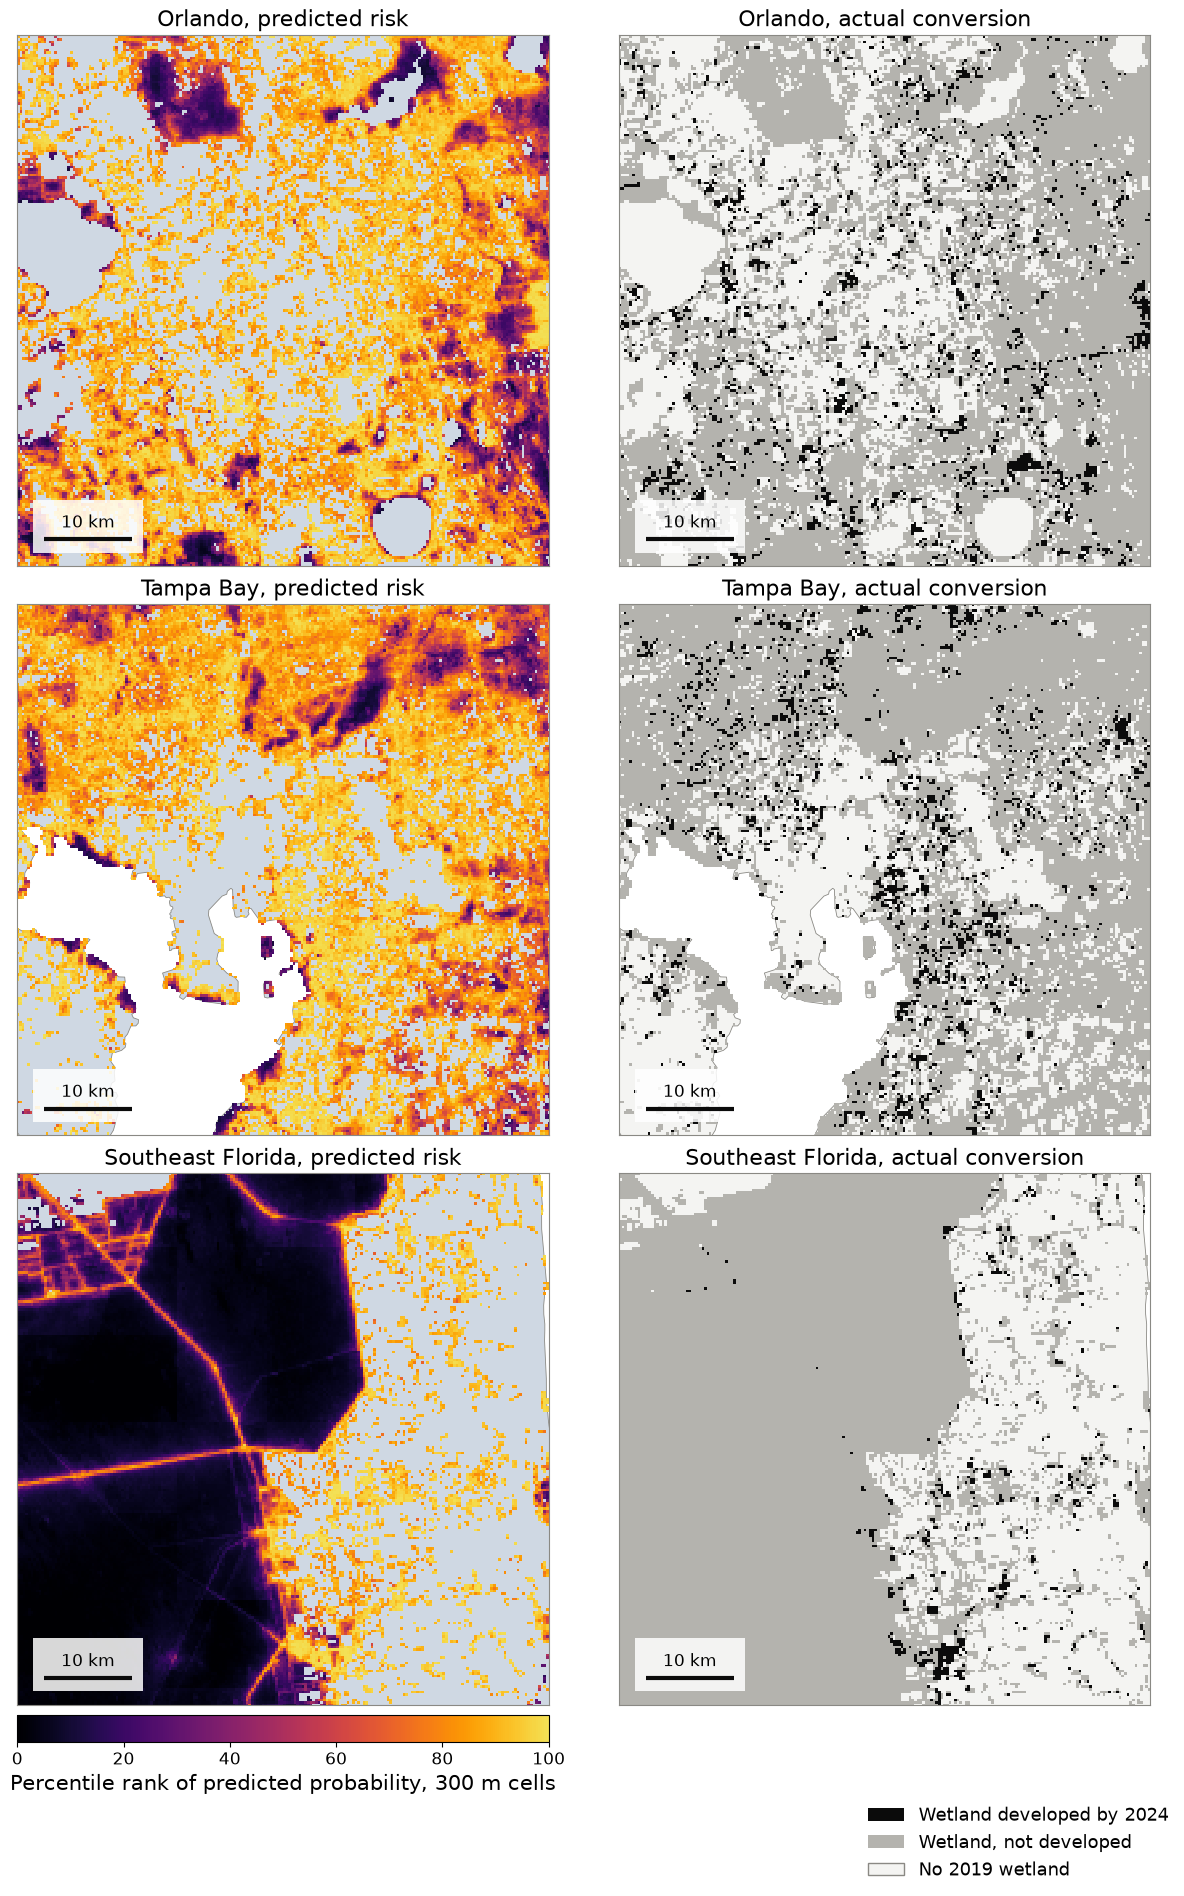

In [81]:
# lon, lat of each inset center; boxes are 60 km on a side
METROS = {"Orlando": (-81.38, 28.54), "Tampa Bay": (-82.40, 27.95), "Southeast Florida": (-80.40, 26.15)}
HALF_KM = 30
to_albers = Transformer.from_crs("EPSG:4326", "EPSG:5070", always_xy=True)


def plot_metro_maps(res):
    g = map_grids[res]
    fig, axes = plt.subplots(len(METROS), 2, figsize=(12, 6.3 * len(METROS)), layout="constrained")
    for (name, (lon, lat)), (ax_p, ax_t) in zip(METROS.items(), axes):
        cx, cy = np.array(to_albers.transform(lon, lat)) / 1000
        lims = dict(xlim=(cx - HALF_KM, cx + HALF_KM), ylim=(cy - HALF_KM, cy + HALF_KM), scale_km=10)
        im = draw_map(ax_p, g, "rank", **lims)
        ax_p.set_title(f"{name}, predicted risk")
        draw_map(ax_t, g, "truth", **lims)
        ax_t.set_title(f"{name}, actual conversion")
    cb = fig.colorbar(im, ax=axes[-1, 0], location="bottom", fraction=0.05, pad=0.02)
    cb.set_label(f"Percentile rank of predicted probability, {RES_TITLE[res]}")
    fig.legend(handles=TRUTH_HANDLES, frameon=False, loc="outside lower right", ncol=1, fontsize=13)
    fig.savefig(FIG_DIR / f"map_val_rank_metros_{res}{FIG_SUFFIX[res]}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()


plot_metro_maps("300m")

# Map of 3 km validation predictions

Same maps as above for the 3 km BCE run (`results/hurdle_clf_mlp_3km_bce`), same color scales and the same 60 km metro boxes so the two resolutions can sit side by side on a slide.

Rank here is percentile among the 23,900 validation cells at 3 km, so a color means the same thing relative to its own resolution but not the same probability as the 300 m map. The positive rate is also very different: 28.6% of 3 km cells had any conversion, against 3.06% at 300 m, because a 3 km cell holds 100 times the area and only needs one converted wetland pixel to count. Expect a lot more black on the actual conversion map.

A 60 km box is only 20 cells across at 3 km, so the insets are blocky. That is the real resolution of the model, not a plotting choice.

At 3 km the blocks rarely line up with the cell grid, so 42% of cells are cut short at a block edge, and snapping to a 3 km grid would hide 29% of them behind a neighbor. So these maps draw every cell as a rectangle at its exact footprint instead of as a raster. The narrow cells along block edges are real cells the model scored, and they show up as thin strips.

3km: grid 231 x 270, 16,951 squares drawn from 23,900 cells (29.1% hidden behind a neighbor)
3km: drawing all 23,900 cells at their exact footprint, 42.3% of them cut short at a block edge


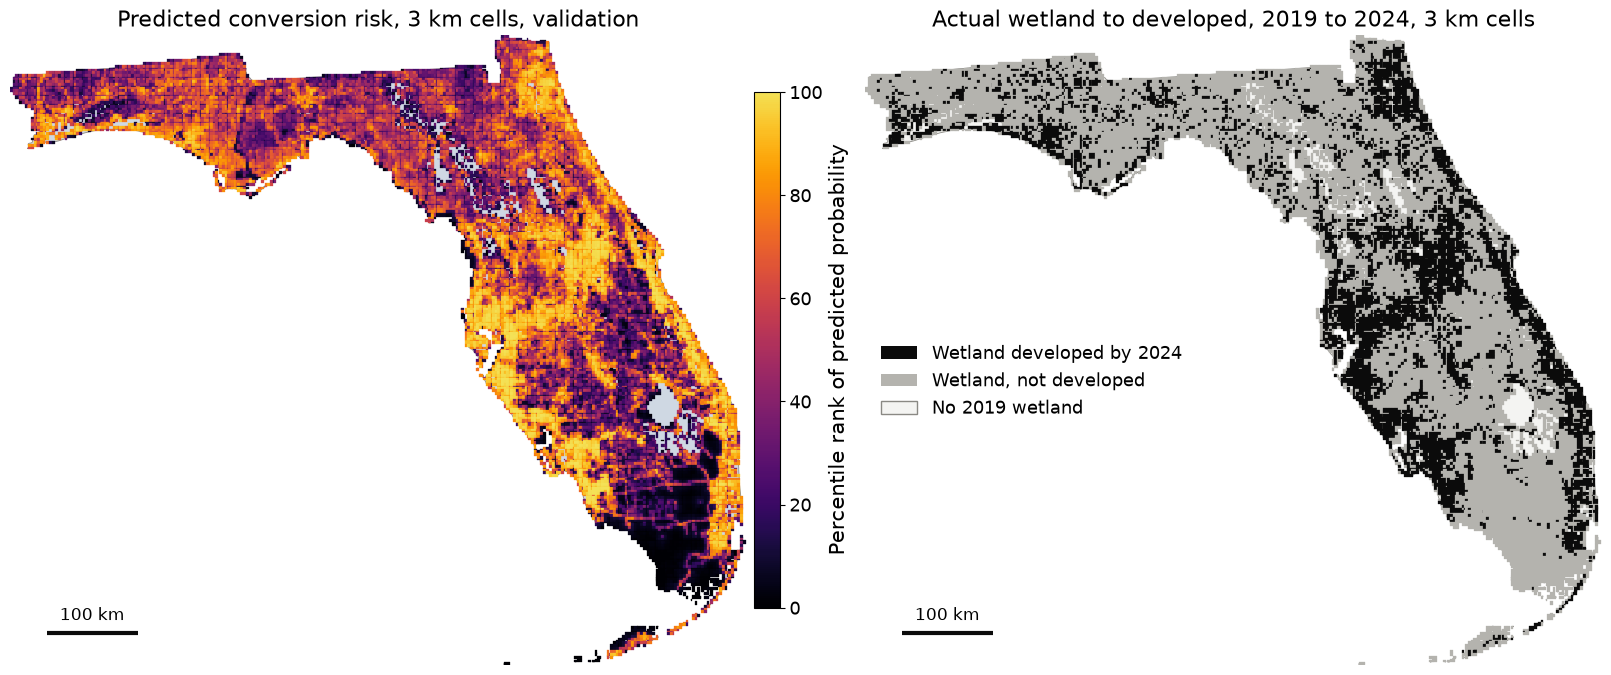

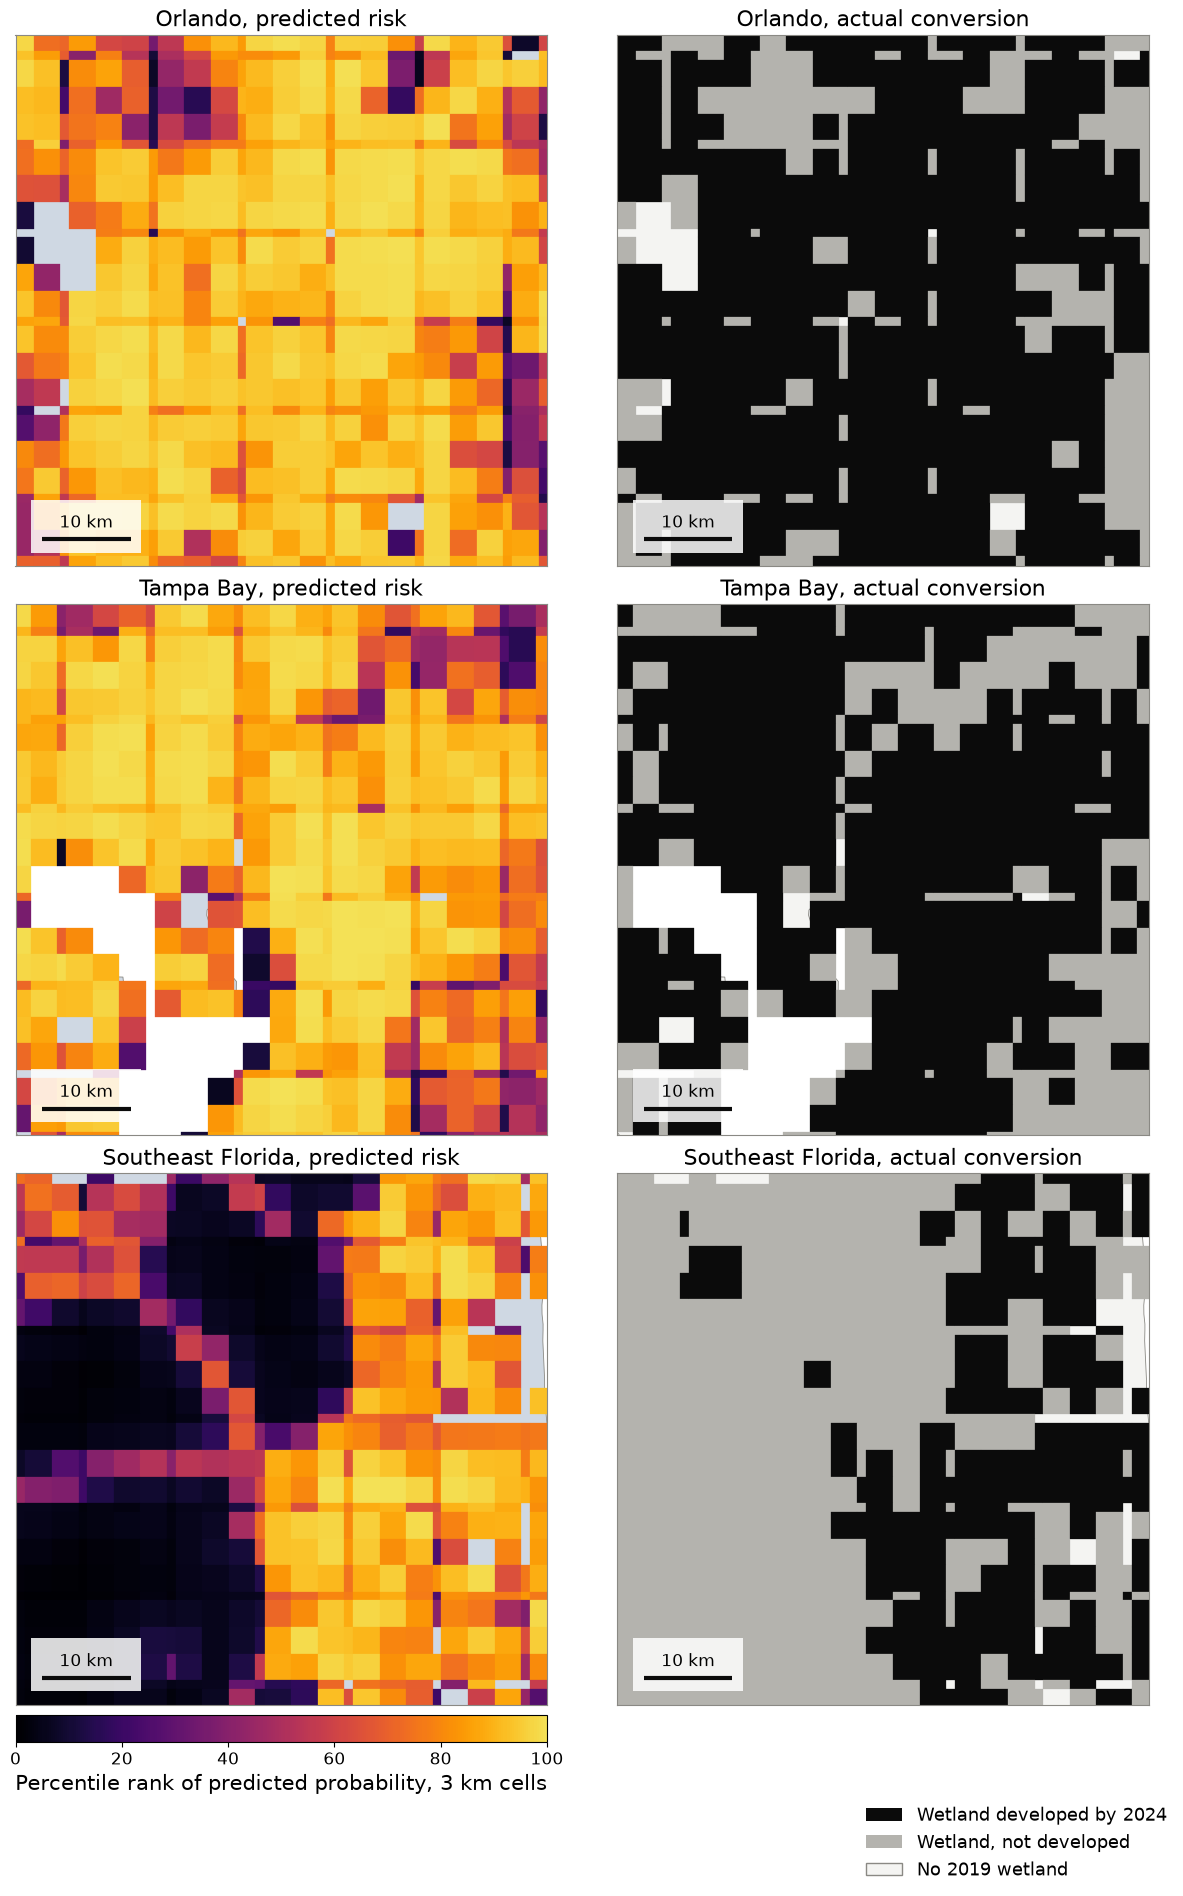

In [82]:
map_grids["3km"] = build_map_grids("3km", exact=True)
plot_state_map("3km")
plot_metro_maps("3km")

# Map of validation cells above a probability cutoff

Only validation cells whose predicted probability clears a cutoff are drawn: above 0.15 for the 300 m run and above 0.5 for the 3 km run. Each drawn cell is colored by what actually happened. Black cells were flagged and did convert (hits). Orange cells were flagged but had no 2019 wetland developed by 2024 (false alarms). Cells below the cutoff aren't drawn, so converted cells the model missed don't show up here; the recall column in the table below counts them.

Neither cutoff is a tuned operating point. Both runs are BCE on stratified batches with no calibration step, so the probabilities are shifted toward the sampled positive rate rather than the real one, and 0.15 versus 0.5 don't mean the same thing across the two runs. Treat these as "the cells the model ranks highest", and read precision against each run's positive rate (3.06% at 300 m, 28.6% at 3 km), not against each other.

The cutoff is applied to probabilities pooled from 5 fold models, and each model can sit at a slightly different scale, so one fold's region can look denser than its neighbors just because that model runs hotter. At state scale a 300 m cell is about one pixel, so neighbors overlap on screen. Cells are drawn in a random order so neither class always wins the overlap, but in dense clusters the map still can't show the exact mix. The counts in the legend are the real numbers.

Every cell is drawn at its exact footprint, the same way as the 3 km rank maps above, so cells cut short at block edges show up as thin strips.

In [83]:
MAP_THRESHOLD = {"300m": 0.15, "3km": 0.5}

rows = []
for res, thr in MAP_THRESHOLD.items():
    v = val_preds[res]
    flag, y = v["prob"].to_numpy() > thr, v["y"].to_numpy().astype(bool)
    tp, fp, fn = (flag & y).sum(), (flag & ~y).sum(), (~flag & y).sum()
    rows.append(dict(resolution=res, threshold=thr, n_val_cells=len(v), positive_rate=y.mean(),
                     n_flagged=flag.sum(), flagged_converted=tp, flagged_not_converted=fp,
                     missed_converted=fn, precision=tp / (tp + fp), recall=tp / (tp + fn)))
threshold_summary = pd.DataFrame(rows).set_index("resolution")
display(threshold_summary.round(3))

,threshold,n_val_cells,positive_rate,n_flagged,flagged_converted,flagged_not_converted,missed_converted,precision,recall
resolution,,,,,,,,,
300m,0.15,1170463,0.031,63315,20177,43138,15675,0.319,0.563
3km,0.50,23900,0.286,5885,4700,1185,2135,0.799,0.688


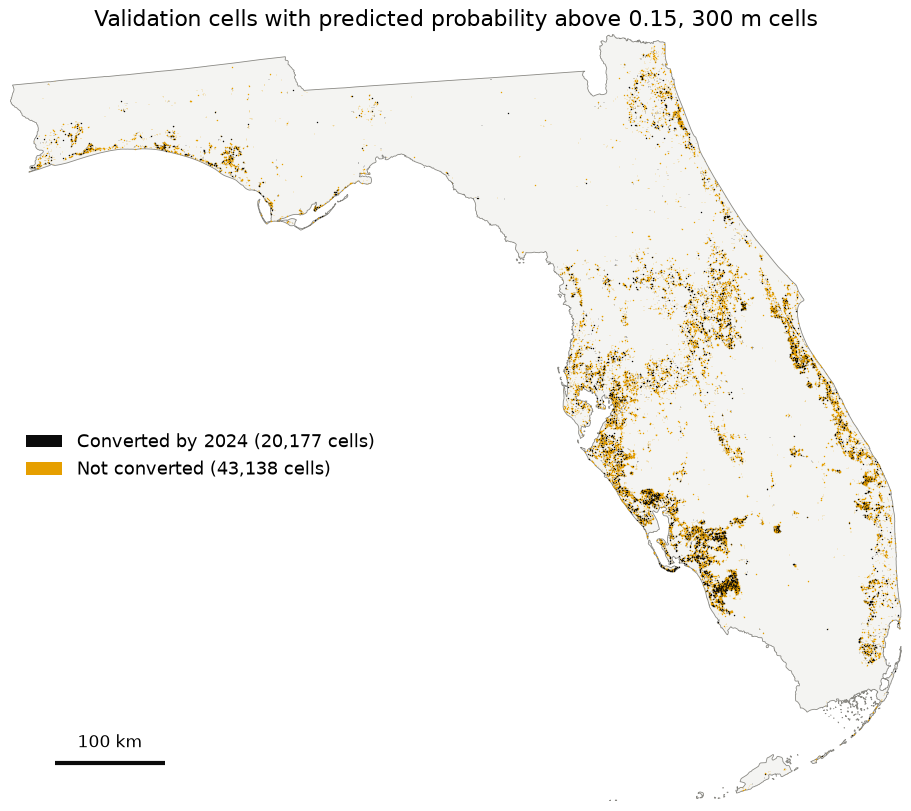

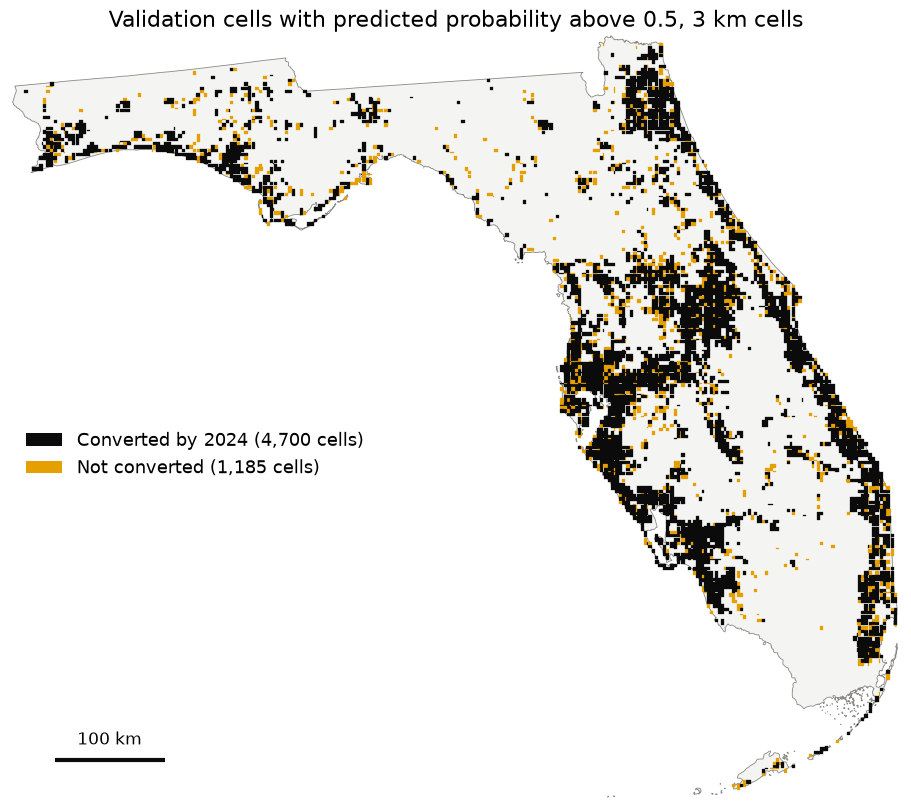

In [84]:
# Okabe Ito orange: the truth map gray disappears into the pale land once cells are a pixel wide
FLAG_NOT_CONVERTED_COLOR = "#E69F00"
FLAG_CONVERTED_COLOR = CONVERTED_COLOR


def flagged_cell_rectangles(res, thr):
    """Exact footprints (EPSG:5070 km) of validation cells with prob above thr, and whether each converted."""
    m = json.loads((RUNS[res] / "manifest.json").read_text())["cells"]
    cell_dir = ROOT / m["path"]
    verts = cell_rectangles_km(np.load(cell_dir / "cell_xy.npy"), np.load(cell_dir / "cell_rowcol.npy"),
                               np.load(cell_dir / "footprint_px.npy"), m["cell_size_m"] // PIXEL_M)
    v = val_preds[res]
    f = v[v["prob"] > thr]
    return verts[f["cell_idx"].to_numpy()], f["y"].to_numpy().astype(bool)


def plot_threshold_map(res, thr, scale_km=100):
    verts, conv = flagged_cell_rectangles(res, thr)
    fig, ax = plt.subplots(figsize=(9, 8), layout="constrained")
    fl.plot(ax=ax, color=LAND_COLOR, edgecolor="#8a8984", linewidth=0.6, zorder=1)
    # random draw order, since drawing one class last makes it look like the majority wherever cells overlap
    order = np.random.default_rng(0).permutation(len(conv))
    colors = np.where(conv[order], FLAG_CONVERTED_COLOR, FLAG_NOT_CONVERTED_COLOR)
    ax.add_collection(plt.matplotlib.collections.PolyCollection(
        verts[order], facecolors=colors, edgecolors="face", linewidths=0.2, zorder=2))

    extent = map_grids[res]["extent_km"]
    ax.set_xlim(extent[:2]); ax.set_ylim(extent[2:])
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    x_lo, x_hi = ax.get_xlim(); y_lo, y_hi = ax.get_ylim()
    w, h = x_hi - x_lo, y_hi - y_lo
    bx, by = x_lo + 0.05 * w, y_lo + 0.05 * h
    ax.plot([bx, bx + scale_km], [by, by], color="#0b0b0b", lw=3, zorder=4, solid_capstyle="butt")
    ax.text(bx + scale_km / 2, by + 0.015 * h, f"{scale_km} km", ha="center", va="bottom", fontsize=12, zorder=4)

    handles = [plt.matplotlib.patches.Patch(facecolor=FLAG_CONVERTED_COLOR,
                                            label=f"Converted by 2024 ({conv.sum():,} cells)"),
               plt.matplotlib.patches.Patch(facecolor=FLAG_NOT_CONVERTED_COLOR,
                                            label=f"Not converted ({(~conv).sum():,} cells)")]
    # the Gulf, west of the peninsula, is empty space for the legend
    ax.legend(handles=handles, frameon=False, loc="center left", bbox_to_anchor=(0.0, 0.45), fontsize=13)
    ax.set_title(f"Validation cells with predicted probability above {thr}, {RES_TITLE[res]}")
    fig.savefig(FIG_DIR / f"map_val_above_{thr}_{res}{FIG_SUFFIX[res]}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()


for res, thr in MAP_THRESHOLD.items():
    plot_threshold_map(res, thr)

# What separates hits, misses and false alarms at the 0.15 cutoff, 300 m

All 300 m validation cells (5 folds pooled, each cell scored once, by the model that never trained on its block) are split by the same 0.15 cutoff as the map above:

| | actually converted | not converted |
|---|---|---|
| p > 0.15 | TP | FP |
| p ≤ 0.15 | FN | TN |

Only full 300 m cells (`footprint_px == 100`) are kept. Cells cut short at a block edge are dropped, since a smaller footprint would shrink every count below for reasons unrelated to the model. That removes 58,736 of 1,170,463 cells. The cutoff isn't a tuned operating point (no calibration step, see above), so read the groups as ranked high versus ranked low, not as a classifier ready to deploy.

Each figure compares the four groups on one cell property:

1. 2019 wetland pixels (30 m) in the cell, `n_wetland`.
2. Distance from the cell's nearest 2019 wetland pixel to 2019 developed land, `dist_min`, in meters on a log scale. This is a model input. Distance runs pixel center to pixel center, so 30 m is the floor: the wetland pixel touches developed land. Most flagged cells sit right on that floor, so their violins collapse to a line, and the tick labels give each group's share at 30 m.
3. How many other 300 m cells within 3 km actually converted 2019 to 2024. Distance is center to center and the cell itself is left out. Neighbors include partial cells and cells from every fold. This uses the neighbors' true labels, so it shows how conversion clusters in space. The model never saw it.
4. 30 m NLCD pixels inside the cell that went from not developed (any class outside 21 to 24) in 2017 to developed in 2019, with valid data in both years. Source is Annual NLCD Collection 1 v2 (`data/NLCD/Annual_NLCD_LndCov_{2017,2019}_CU_C1V2`).
5. The same 2017 to 2019 count over a square ring around the cell, with the cell's own pixels left out. The ring is 33 pixels wide (990 m, the closest whole number of pixels to 1 km), so it covers 76 × 76 pixels minus the 100 in the cell, or 5,676 pixels.

Counts 4 and 5 come from `dev_change_2017_2019_cell_pct.npy` and `dev_change_2017_2019_ring1km_pct.npy` in the cell folder, which `build_cell_dev_change.py` built from those two NLCD rasters. They're stored as percent of the area, and for a full cell that converts back to an exact pixel count; the code checks that it lands on whole numbers. Both cover years before the 2019 to 2024 target, so they can't leak the label.

The count panels use a log(1 + x) axis because most cells sit at or near 0. A violin can't show a spike at exactly 0 well, so the tick labels give each group's share of cells above 0, and the table has the medians. The white dot is the median and the thick bar is the interquartile range. Every violin is drawn at the same width, so compare shapes, not areas: TN holds over a million cells and TP about 20,000.

In [85]:
from scipy.spatial import cKDTree

CM_THRESHOLD = MAP_THRESHOLD["300m"]
NEIGHBOR_RADIUS_M = 3000
# ring is 33 px out from each edge of a 10 x 10 px cell, see dev_change_2017_2019 in the cell manifest
RING_PX = 33
RING_AREA_PX = (10 + 2 * RING_PX) ** 2 - 100

cells_300m = json.loads((RUNS["300m"] / "manifest.json").read_text())["cells"]
cell_dir_300m = ROOT / cells_300m["path"]
cell_manifest_300m = json.loads((cell_dir_300m / "manifest.json").read_text())
assert cell_manifest_300m["added_features"]["dev_change_2017_2019"]["ring_px"] == RING_PX
print("NLCD:", cell_manifest_300m["added_features"]["dev_change_2017_2019"]["nlcd"])

footprint = np.load(cell_dir_300m / "footprint_px.npy")
cell_xy = np.load(cell_dir_300m / "cell_xy.npy")

v = val_preds["300m"]
assert v["cell_idx"].is_unique and len(v) == len(footprint)
converted = np.zeros(len(footprint), bool)
converted[v["cell_idx"].to_numpy()] = v["y"].to_numpy()

# every cell counts as a neighbor, partial or not; only the cell being scored has to be full
tree = cKDTree(cell_xy[converted])
n_conv_3km = tree.query_ball_point(cell_xy, r=NEIGHBOR_RADIUS_M, return_length=True) - converted

# stored as percent of area; a full cell is 100 px so the cell percent already is the count
dev_cell = np.load(cell_dir_300m / "dev_change_2017_2019_cell_pct.npy").astype(np.float64)
dev_ring = np.load(cell_dir_300m / "dev_change_2017_2019_ring1km_pct.npy").astype(np.float64) * RING_AREA_PX / 100

cm = v[footprint[v["cell_idx"].to_numpy()] == 100].copy()
idx = cm["cell_idx"].to_numpy()
for name, a in (("dev_cell", dev_cell[idx]), ("dev_ring", dev_ring[idx])):
    assert np.abs(a - np.rint(a)).max() < 0.01, f"{name} doesn't land on whole pixels"
    cm[name] = np.rint(a).astype(int)
cm["dist_min"] = np.load(cell_dir_300m / "dist_min.npy")[idx]
cm["n_conv_3km"] = n_conv_3km[idx]

flag, y = cm["prob"].to_numpy() > CM_THRESHOLD, cm["y"].to_numpy().astype(bool)
# flagged groups side by side, so TP and FP sit next to each other in the plots
CM_GROUPS = ["TP", "FP", "FN", "TN"]
cm["group"] = pd.Categorical(np.select([flag & y, flag & ~y, ~flag & y], ["TP", "FP", "FN"], "TN"), CM_GROUPS)
print(f"{len(cm):,} full cells kept, {len(v) - len(cm):,} partial cells dropped, "
      f"positive rate {y.mean():.2%}, precision {(flag & y).sum() / flag.sum():.3f}, recall {(flag & y).sum() / y.sum():.3f}")

CM_METRICS = ["n_wetland", "dist_min", "n_conv_3km", "dev_cell", "dev_ring"]
g = cm.groupby("group", observed=True)
summary = pd.concat({col: g[col].agg(median="median", mean="mean",
                                     q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75),
                                     share_above_0=lambda s: (s > 0).mean())
                     for col in CM_METRICS}, axis=1)
# rows are property and statistic, columns are the four groups
summary = summary.T
summary.loc[("all", "n_cells"), :] = g.size()
display(summary.round(3))

NLCD: ['Annual_NLCD_LndCov_2017_CU_C1V2.tif', 'Annual_NLCD_LndCov_2019_CU_C1V2.tif']


1,111,727 full cells kept, 58,736 partial cells dropped, positive rate 3.14%, precision 0.321, recall 0.566


group                            TP         FP         FN           TN
n_wetland  median            26.000     25.000     28.000       51.000
           mean              32.369     31.269     35.609       53.722
           q25               12.000     11.000      9.000       18.000
           q75               48.000     47.000     58.000       96.000
           share_above_0      1.000      1.000      1.000        1.000
dist_min   median            30.000     30.000     30.000      240.000
           mean              30.353     30.707     64.663     1023.971
           q25               30.000     30.000     30.000       30.000
           q75               30.000     30.000     30.000      724.983
           share_above_0      1.000      1.000      1.000        1.000
n_conv_3km median            42.000     28.000     21.000        0.000
           mean              53.460     35.205     27.776        4.510
           q25               24.000     14.000      8.000        0.000
           q75               69.000     47.000     40.000        3.000
           share_above_0      0.998      0.989      0.966        0.495
dev_cell   median             0.000      0.000      0.000        0.000
           mean               3.163      1.753      1.331        0.133
           q25                0.000      0.000      0.000        0.000
           q75                2.000      1.000      1.000        0.000
           share_above_0      0.401      0.273      0.272        0.044
dev_ring   median            31.000     22.000     22.000        1.000
           mean              93.512     68.221     82.102       10.991
           q25               12.000      9.000      7.000        0.000
           q75               85.000     59.000     76.000        6.000
           share_above_0      0.990      0.976      0.951        0.531
all        n_cells        19730.000  41779.000  15151.000  1035067.000

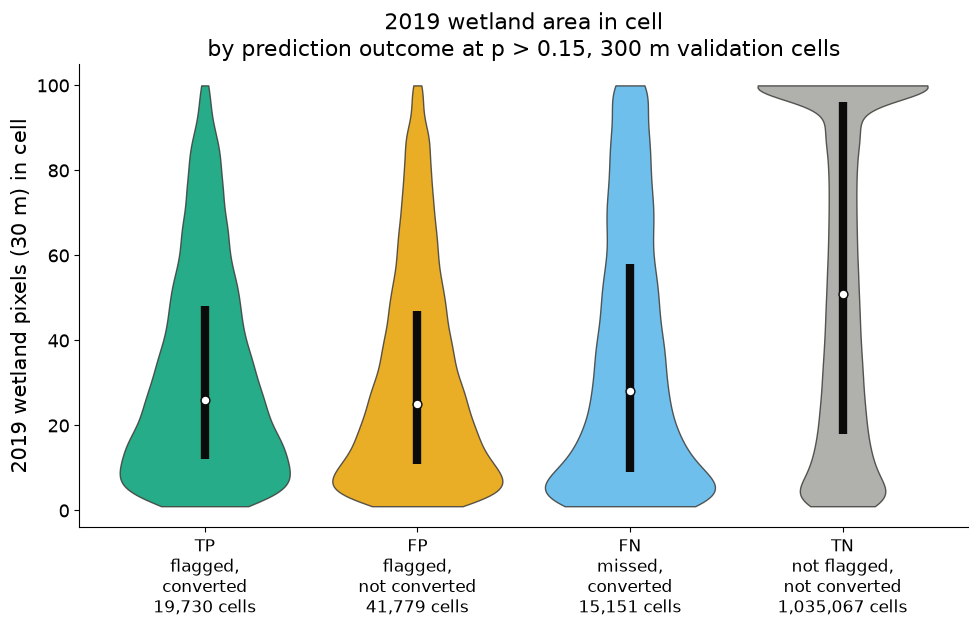

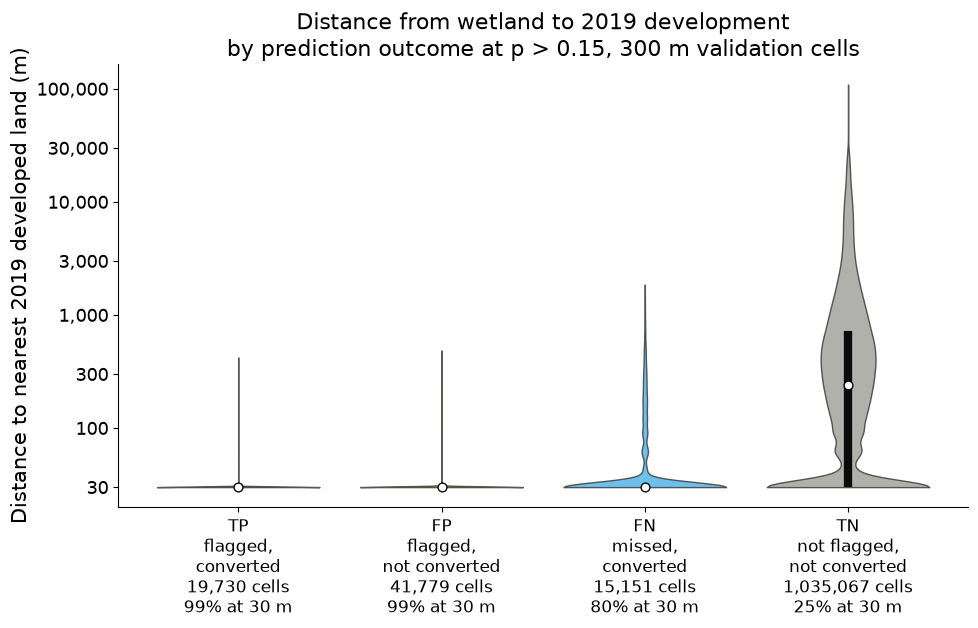

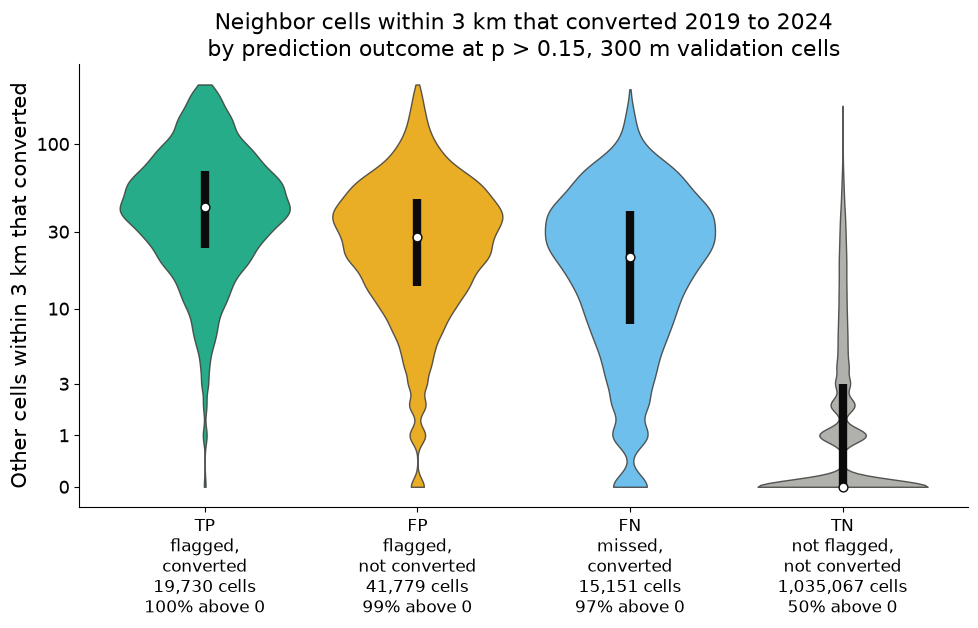

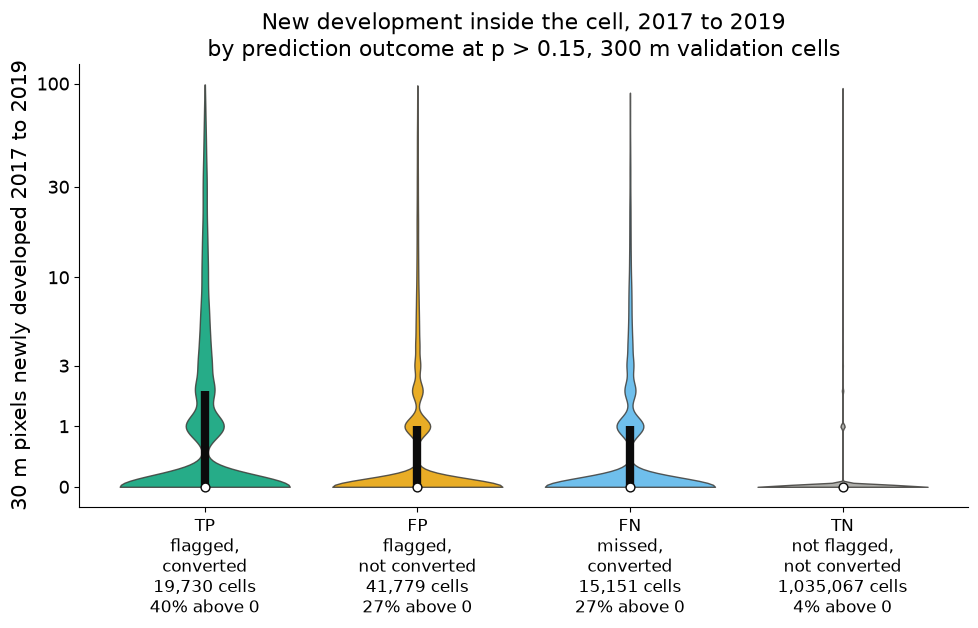

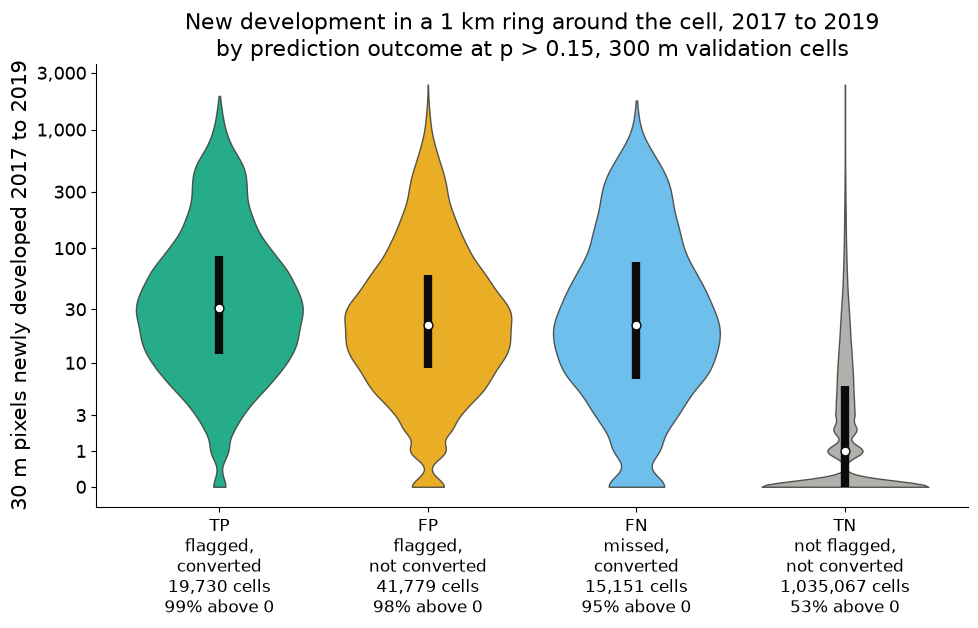

In [86]:
# Okabe Ito; FP matches the false alarm orange on the cutoff map above, TN is the same gray as "not converted"
CM_COLORS = {"TP": "#009E73", "FN": "#56B4E9", "FP": "#E69F00", "TN": NOT_CONVERTED_COLOR}
CM_NAMES = {"TP": "TP\nflagged,\nconverted", "FN": "FN\nmissed,\nconverted",
            "FP": "FP\nflagged,\nnot converted", "TN": "TN\nnot flagged,\nnot converted"}
# KDE cost grows with cell count; past this many the shape doesn't change, so draw the violin from a subsample.
# Medians, quartiles and the table use every cell.
KDE_MAX = 200_000
# dist_min is pixel center to pixel center, so a wetland pixel touching development is at 30 m, the floor
ADJACENT_M = 30


def violin_by_group(df, col, ylabel, title, scale="linear"):
    """scale is "linear", "log" (values > 0) or "log1p" (counts with zeros)."""
    fwd = {"linear": lambda a: a, "log": np.log10, "log1p": lambda a: np.log10(1 + a)}[scale]
    rng = np.random.default_rng(0)
    data, ticks = [], []
    for grp in CM_GROUPS:
        a = df.loc[df["group"] == grp, col].to_numpy().astype(float)
        kde_a = rng.choice(a, KDE_MAX, replace=False) if len(a) > KDE_MAX else a
        data.append((fwd(a), fwd(kde_a)))
        t = f"{CM_NAMES[grp]}\n{len(a):,} cells"
        if scale == "log1p":
            t += f"\n{(a > 0).mean():.0%} above 0"
        elif col == "dist_min":
            # most flagged cells sit right on the floor, so the violin there is a flat line
            t += f"\n{(a <= ADJACENT_M).mean():.0%} at {ADJACENT_M} m"
        ticks.append(t)

    fig, ax = plt.subplots(figsize=(10, 6.5))
    x = np.arange(len(CM_GROUPS))
    parts = ax.violinplot([k for _, k in data], positions=x, widths=0.8, showextrema=False, points=200)
    for body, grp in zip(parts["bodies"], CM_GROUPS):
        body.set_facecolor(CM_COLORS[grp]); body.set_edgecolor("#3d3c39"); body.set_alpha(0.85); body.set_linewidth(1)
    for xi, (full, _) in zip(x, data):
        q25, q50, q75 = np.percentile(full, [25, 50, 75])
        ax.vlines(xi, q25, q75, color="#0b0b0b", lw=6, zorder=3)
        ax.scatter(xi, q50, s=40, color="white", edgecolor="#0b0b0b", zorder=4)

    if scale != "linear":
        lo, hi = ax.get_ylim()
        vals = np.array([0, 1, 3, 10, 30, 100, 300, 1000, 3000, 10_000, 30_000, 100_000])
        if scale == "log":
            vals = vals[vals > 0]
        tv = fwd(vals.astype(float))
        keep = (tv >= lo) & (tv <= hi)
        ax.set_yticks(tv[keep], [f"{v:,}" for v in vals[keep]])
    ax.set_xticks(x, ticks)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    fig.tight_layout()
    return fig


VIOLINS = [
    ("n_wetland", "2019 wetland pixels (30 m) in cell", "2019 wetland area in cell", "linear"),
    ("dist_min", "Distance to nearest 2019 developed land (m)", "Distance from wetland to 2019 development", "log"),
    ("n_conv_3km", "Other cells within 3 km that converted", "Neighbor cells within 3 km that converted 2019 to 2024", "log1p"),
    ("dev_cell", "30 m pixels newly developed 2017 to 2019", "New development inside the cell, 2017 to 2019", "log1p"),
    ("dev_ring", "30 m pixels newly developed 2017 to 2019", "New development in a 1 km ring around the cell, 2017 to 2019", "log1p"),
]
for col, ylabel, what, scale in VIOLINS:
    title = f"{what}\nby prediction outcome at p > {CM_THRESHOLD}, 300 m validation cells"
    fig = violin_by_group(cm, col, ylabel, title, scale)
    fig.savefig(FIG_DIR / f"violin_cm_{col}_300m{FIG_SUFFIX['300m']}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

# AUPRC with spatial tolerance, 300 m

How much better does the 300 m model look if a prediction only has to land near a conversion, not on the exact cell? Each cell gets a square window of (2k + 1) × (2k + 1) cells centered on it, so k = 1 is the 3 × 3 block of 900 m, diagonals included. k runs from 0 (the plain per cell AUPRC) to 5, an 11 × 11 window of 3.3 km, the first size past 3 km. A cell is in another cell's window if its center falls inside that window's square, so partial cells at block edges get picked up wherever they sit.

There are two ways of scoring with a window. Both are computed per fold and then averaged over the 5 folds.

**Window max (the main number).** Every cell's score becomes the max predicted probability in its window, and its label becomes "any conversion in the window". Then it's plain AUPRC over all cells. This asks the model "will anything in this 900 m square convert", with the square sliding to every cell. It treats both kinds of error the same way: a flagged cell near a conversion counts as a hit, and a conversion with a flagged neighbor counts as found.

**Positives only (the rule as first stated).** Only converted cells get the window max. Every other cell keeps its own probability and label. This is lopsided: a converted cell gets the best of up to 121 scores while a negative gets one, so converted cells rise to the top even when the scores carry no information. The shuffled baseline in the table shows how much.

The baseline for each method is the AUPRC you get by shuffling the probabilities within the fold, then putting them through the same windowing. That is what a model with no skill would score under the same rule. For window max it lands on the share of cells with a conversion in their window, so it plays the same role as the positive rate does for plain AUPRC. The figure shows only window max; positives only and both baselines are in the table. Read each line against its own baseline column, not against 0. Points in the figure are the mean over the 5 folds and error bars the standard deviation across folds. `mean_window_cells` in the table is how many cells a window actually holds on average, fewer than (2k + 1)² because of gaps with no 2019 wetland and fold edges.

Windows only use cells from the same fold. A cell from another fold was scored by a model that trained on this cell's block, including this cell's label, and its probability would leak that label into the window. Cells near a fold edge therefore have smaller windows, which makes these numbers slightly conservative.

This is a sliding window, not a retiled grid. So k = 1 isn't the same as training a 900 m model, and k = 5 isn't the same as the 3 km run, which has fixed tiles, its own model, and a 28.6% positive rate.

In [87]:
CELL_M = cells_300m["cell_size_m"]
TOL_K = range(6)  # 2k + 1 cells across: 300 m up to 3.3 km, the first window past 3 km


def window_max(pairs, p, y):
    """Max prob and any(label) over each cell's window. pairs are (i, j) neighbors, each listed once."""
    m, L = p.copy(), y.astype(np.int8)
    for a, b in ((pairs[:, 0], pairs[:, 1]), (pairs[:, 1], pairs[:, 0])):
        np.maximum.at(m, a, p[b])
        np.maximum.at(L, a, y[b].astype(np.int8))
    return m, L.astype(bool)


rows = []
for fold, f in val_preds["300m"].groupby("fold"):
    p = f["prob"].to_numpy().astype(np.float64)
    y = f["y"].to_numpy().astype(bool)
    # same fold only: a neighbor from another fold was scored by a model trained on this cell's label
    tree = cKDTree(cell_xy[f["cell_idx"].to_numpy()])
    p_shuf = np.random.default_rng(fold).permutation(p)
    for k in TOL_K:
        # Chebyshev distance, so the window is a square; the 1 m margin keeps the next ring of centers out
        pairs = (tree.query_pairs((k + 0.5) * CELL_M - 1, p=np.inf, output_type="ndarray") if k
                 else np.empty((0, 2), dtype=np.int64))
        m, L = window_max(pairs, p, y)
        m_shuf, _ = window_max(pairs, p_shuf, y)
        rows.append(dict(
            fold=fold, k=k, window_m=(2 * k + 1) * CELL_M, n_cells=len(p), mean_window_cells=1 + 2 * len(pairs) / len(p),
            window_positive_rate=L.mean(),
            auprc_window_max=average_precision_score(L, m),
            auprc_window_max_shuffled=average_precision_score(L, m_shuf),
            auprc_pos_only=average_precision_score(y, np.where(y, m, p)),
            auprc_pos_only_shuffled=average_precision_score(y, np.where(y, m_shuf, p_shuf)),
        ))
tol_per_fold = pd.DataFrame(rows)

# k = 0 has to reproduce the per fold AUPRC the training run logged
logged = pd.read_csv(RUNS["300m"] / "fold_summary.csv").set_index("fold")["auprc"]
k0 = tol_per_fold[tol_per_fold["k"] == 0].set_index("fold")
assert np.allclose(k0["auprc_window_max"], logged) and np.allclose(k0["auprc_pos_only"], logged)
print(f"300 m AUPRC, no tolerance: {logged.mean():.3f} ± {logged.std():.3f} over {len(logged)} folds "
      f"(positive rate {k0['window_positive_rate'].mean():.4f})")

tol_summary = tol_per_fold.drop(columns="fold").groupby(["k", "window_m"]).agg(["mean", "std"])
tol_summary = tol_summary.drop(columns=[("n_cells", "std"), ("mean_window_cells", "std")])
display(tol_summary.round(3))

300 m AUPRC, no tolerance: 0.389 ± 0.044 over 5 folds (positive rate 0.0306)


n_cells mean_window_cells window_positive_rate         \
                mean              mean                 mean    std   
k window_m                                                           
0 300       234092.6             1.000                0.031  0.003   
1 900       234092.6             7.820                0.106  0.008   
2 1500      234092.6            20.406                0.175  0.011   
3 2100      234092.6            38.232                0.237  0.013   
4 2700      234092.6            60.810                0.292  0.015   
5 3300      234092.6            87.690                0.342  0.016   

           auprc_window_max        auprc_window_max_shuffled         \
                       mean    std                      mean    std   
k window_m                                                            
0 300                 0.389  0.044                     0.031  0.003   
1 900                 0.667  0.034                     0.104  0.008   
2 1500                0.764  0.018                     0.171  0.012   
3 2100                0.808  0.014                     0.231  0.015   
4 2700                0.833  0.015                     0.286  0.020   
5 3300                0.850  0.017                     0.339  0.023   

           auprc_pos_only        auprc_pos_only_shuffled         
                     mean    std                    mean    std  
k window_m                                                       
0 300               0.389  0.044                   0.031  0.003  
1 900               0.606  0.039                   0.140  0.013  
2 1500              0.701  0.033                   0.277  0.023  
3 2100              0.759  0.028                   0.405  0.031  
4 2700              0.798  0.025                   0.508  0.035  
5 3300              0.826  0.022                   0.590  0.035

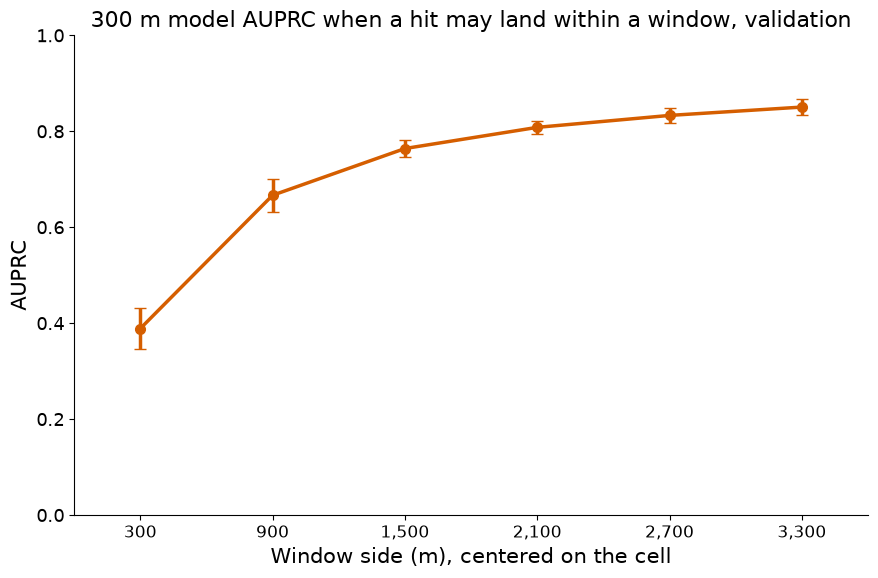

In [88]:
def plot_tolerance_auprc(s):
    fig, ax = plt.subplots(figsize=(9, 6))
    x = s.index.get_level_values("window_m")
    ax.errorbar(x, s[("auprc_window_max", "mean")], yerr=s[("auprc_window_max", "std")], color=VAL_COLOR,
                lw=2.5, marker="o", ms=7, capsize=4, zorder=3)
    ax.set_xticks(x, [f"{w:,}" for w in x])
    ax.set_xlim(0, x.max() + CELL_M)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Window side (m), centered on the cell")
    ax.set_ylabel("AUPRC")
    ax.set_title("300 m model AUPRC when a hit may land within a window, validation")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    fig.tight_layout()
    return fig


fig = plot_tolerance_auprc(tol_summary)
fig.savefig(FIG_DIR / f"auprc_spatial_tolerance_300m{FIG_SUFFIX['300m']}.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()